# Inverse designed grating coupler

Inverse design of grating coupler on SOI for angled fiber. (inverse design not available in free version)

## Config

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt

import gdsfactory as gf
from gdsfactory.technology import LogicalLayer, LayerLevel, LayerStack
import luminescent as lumi

path = os.path.join("runs", "GC_invd")

wl = 1.55
bandwidth = 0.01
nwls = 3
wls = np.linspace(wl - bandwidth / 2, wl + bandwidth / 2, nwls)

# simulation parameters
nres = 6
boundaries = ["PML", ["PEC", "PML"], "PML"]
PML_decay = [0.01, 0.3, 0.01]
courant = 0.95
# stop_decay=.001
stop_decay=None

# horizontal dimensions
D = 10.4  # mode field diameter, SMF-28
R =  D  # beam frame 
flare = 25  # waveguide flare full angle (deg)
W = 3 * D
# L = W
L = W/2/np.tan(flare/2/180*np.pi)
w_wg = 0.5
l_wg =1
l_flare = .5

margin = .5
nox=1.44
# vertical dimensions
theta = 7 * np.pi / 180 # beam angle
h_wg = 0.22
h_etch = 0.08
h_slab = h_wg-h_etch
# h_box = 2.0  # buried oxide
h_box = (1 + .5) *wl / (2 * nox * np.cos( theta))
h_sub = 0.3  # substrate thickness in domain

zmargin = .6
port_offset = 0.3
source_offset = 0.3
z_port = h_wg + port_offset

zmin = -h_box - h_sub
zmax = h_wg + port_offset + source_offset

# movie parameters
shot_every = 10

views = [
    lumi.view("Ey", y=0, z=h_slab+h_etch/2,mirrors = ["y-"]),
]

# materials
core = "Si"
clad = "SiO2"
materials = {
    "Si": lumi.material(3.45),
    "SiO2": lumi.material(1.44),
}

n_core = materials[core]["n"]
n_clad = materials[clad]["n"]
lambda_core = wl / n_core
lambda_clad = wl / n_clad
dx = lambda_core / nres

background = clad
materials["design"] = lumi.placeholder_material(n_core)

# layer stack. lower mesh order layers override higher mesh order layers.
WG = (1, 0)
CLAD = (2, 0)
SLAB = (102, 0)
DESIGN = (1001, 0)
CONTOUR=(1002,0)

layers = {
    "design": LayerLevel(
        layer=LogicalLayer(layer=DESIGN),
        zmin=h_slab,
        thickness=h_etch,
        material="design",
        mesh_order=1,
    ),
    "rib": LayerLevel(
        layer=LogicalLayer(layer=SLAB),
        zmin=h_slab,
        thickness=h_etch,
        material=core,
        mesh_order=101,
    ),
    "slab": LayerLevel(
        layer=LogicalLayer(layer=SLAB),
        zmin=0,
        thickness=h_slab,
        material=core,
        mesh_order=102,
    ),
    "core": LayerLevel(
        layer=LogicalLayer(layer=WG),
        zmin=0,
        thickness=h_wg,
        material=core,
        mesh_order=200,
    ),
    "substrate": LayerLevel(
        layer=LogicalLayer(layer=CLAD),
        zmin=zmin,
        thickness=h_sub,
        material=core,
        mesh_order=300,
    ),
}
layer_stack = LayerStack(layers=layers)

optimizer = lumi.optimizer(
    stoploss=0.3,
    lowloss=0.5,
    iters=20,
    contrast=0.5,
    momentum=0.7,
)
targets = [
    lumi.target(src="o2@0-", dst="o1@0+", target=1, weight=1 / nwls, wl=wl)
    for wl in wls
]
lmin=.1

lumi backend: None


## Geometry

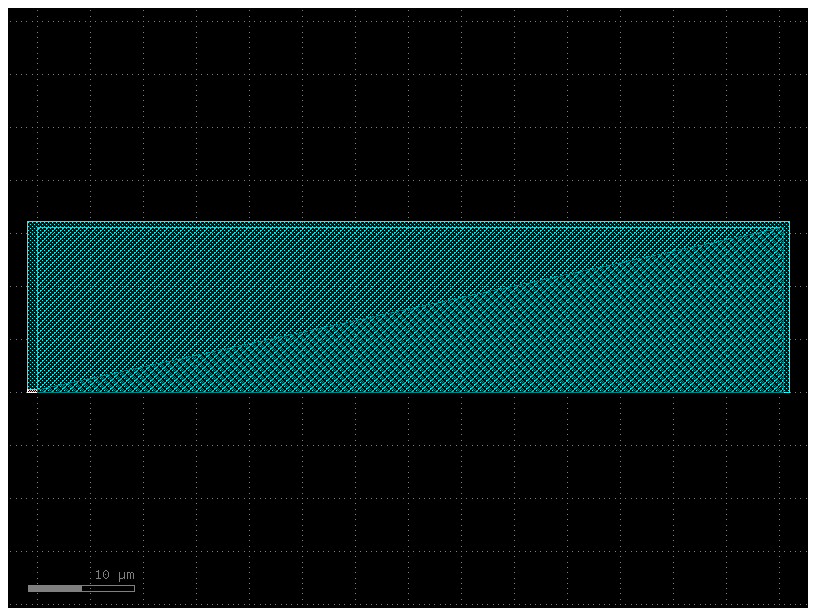

In [2]:
# Build the gdsfactory component to be optimized (upper half, mirrored about y=0).
x_design = -L + R
# x_flare = ox_design - l_flare
# x_wg = x_flare - l_wg

c = gf.Component()
for layer in (DESIGN, ):
    rect = c << gf.components.rectangle(size=(L, W / 2), layer=layer)
    rect.movex(x_design)

# w_flare = w_wg / 2 + l_flare * np.tan(np.radians(flare / 2))
x_wg=x_design-l_wg
p=[(x_design,0),(x_design,w_wg/2),(x_design+L,W/2),(x_design+L,0)]
c.add_polygon([(x_wg, 0), (x_wg, w_wg / 2), (x_design, w_wg / 2), (x_design,0)], layer=WG)
c.add_polygon(p, layer=CONTOUR)
c.add_polygon(p, layer=SLAB)

c << gf.components.bbox(component=c, layer=CLAD, top=margin, right=margin)

c.add_port("o1", center=(x_wg, 0), width=w_wg / 2, orientation=180, layer=WG)


c.plot()

In [3]:
frames = [
    lumi.plane_frame(
        "wg",
        start=[-w_wg / 2 - margin, -zmargin],
        stop=[0, h_wg+zmargin],
        boundaries=[("PML", "PEC"), "PML"],
        wls_mode_solver=[wl],
    ),
    lumi.plane_frame(
        "beam",
        modes=[
            [
                lumi.gaussian_mode(
                    D,
                    n_clad,
                    dx=dx,
                    theta=theta,
                    wl=wl,
                    half="y+",
                    Dlim=2*R,
                )
            ]
        ],
        start=[-R, 0],
        stop=[R, R],
    ),
]

origin = [
    np.sin(theta) * (source_offset + port_offset),
    0,
    h_wg + port_offset + source_offset,
]
basis = [[1, 0, 0], [0, 1, 0], [0, 0, 1]]
sources = [
    lumi.source(
        "o2",
        origin,
        basis,
        wl=wl,
        bandwidth=max(max(wls) - min(wls), wl / 4),
        frame="beam",
    )
]

origin = [np.sin(theta) * (port_offset), 0, h_wg + port_offset]
monitors = [
    lumi.gf_monitor("o1", c, layer_stack, frame="wg"),
    lumi.monitor("o2", origin, basis, frame="beam"),
]


designs = [
    lumi.design(
        name="design",
        lmin =lmin,
        layer=DESIGN,
        contour_layer=CONTOUR,
        fill_material=core,
        void_material=clad,
        component=c,
        layer_stack=layer_stack,
        materials=materials,
        repdims=[3],
        anchordims=[],
    )
]

tmax =     1.2/ wl    * (
        (port_offset + source_offset + 2 * h_box) / np.cos(theta) * n_clad
        + (L + W / 2 + R + l_wg) * n_core
    )    + sources[0]["duration"]

bbox = c.bbox_np().tolist()
bbox[0].append(zmin)
bbox[1].append(zmax)

## Solve

showing modes for wavelength 1.55
mode Boundary conditions: 00A0


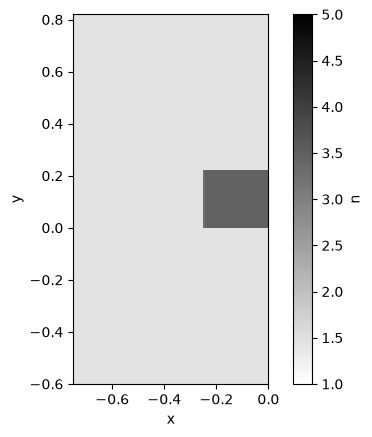

wg/1.55 mode 0 (neff=2.409+0.000j)
saving mode to runs/GC_invd/modes/wg/1.55/0.npz
using simulation folder runs/GC_invd


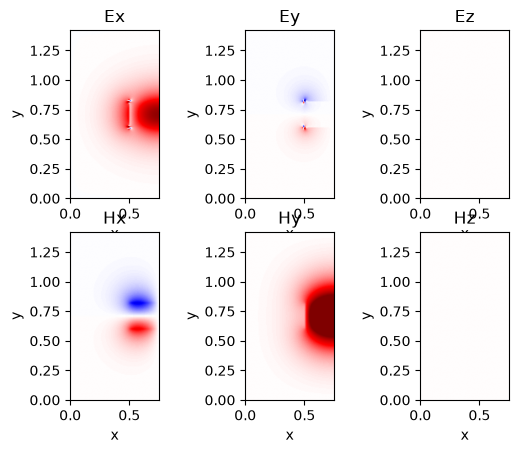

In [4]:
lumi.mesh(path, c, layer_stack, materials, zmin, zmax)
lumi.setup(
    path=path,
    wl=wl,
    wls=wls,
    frames=frames,
    monitors=monitors,
    sources=sources,
    boundaries=boundaries,
    bbox=bbox,
    materials=materials,
    background=background,
    nres=nres,
    tmax=tmax,
    PML_decay=PML_decay,
    courant=courant,
    stop_decay=stop_decay,
    shot_every=shot_every,
    views=views,
    designs=designs,
    targets=targets,
    optimizer=optimizer,
    # load_designs=['design']
)

## Movie


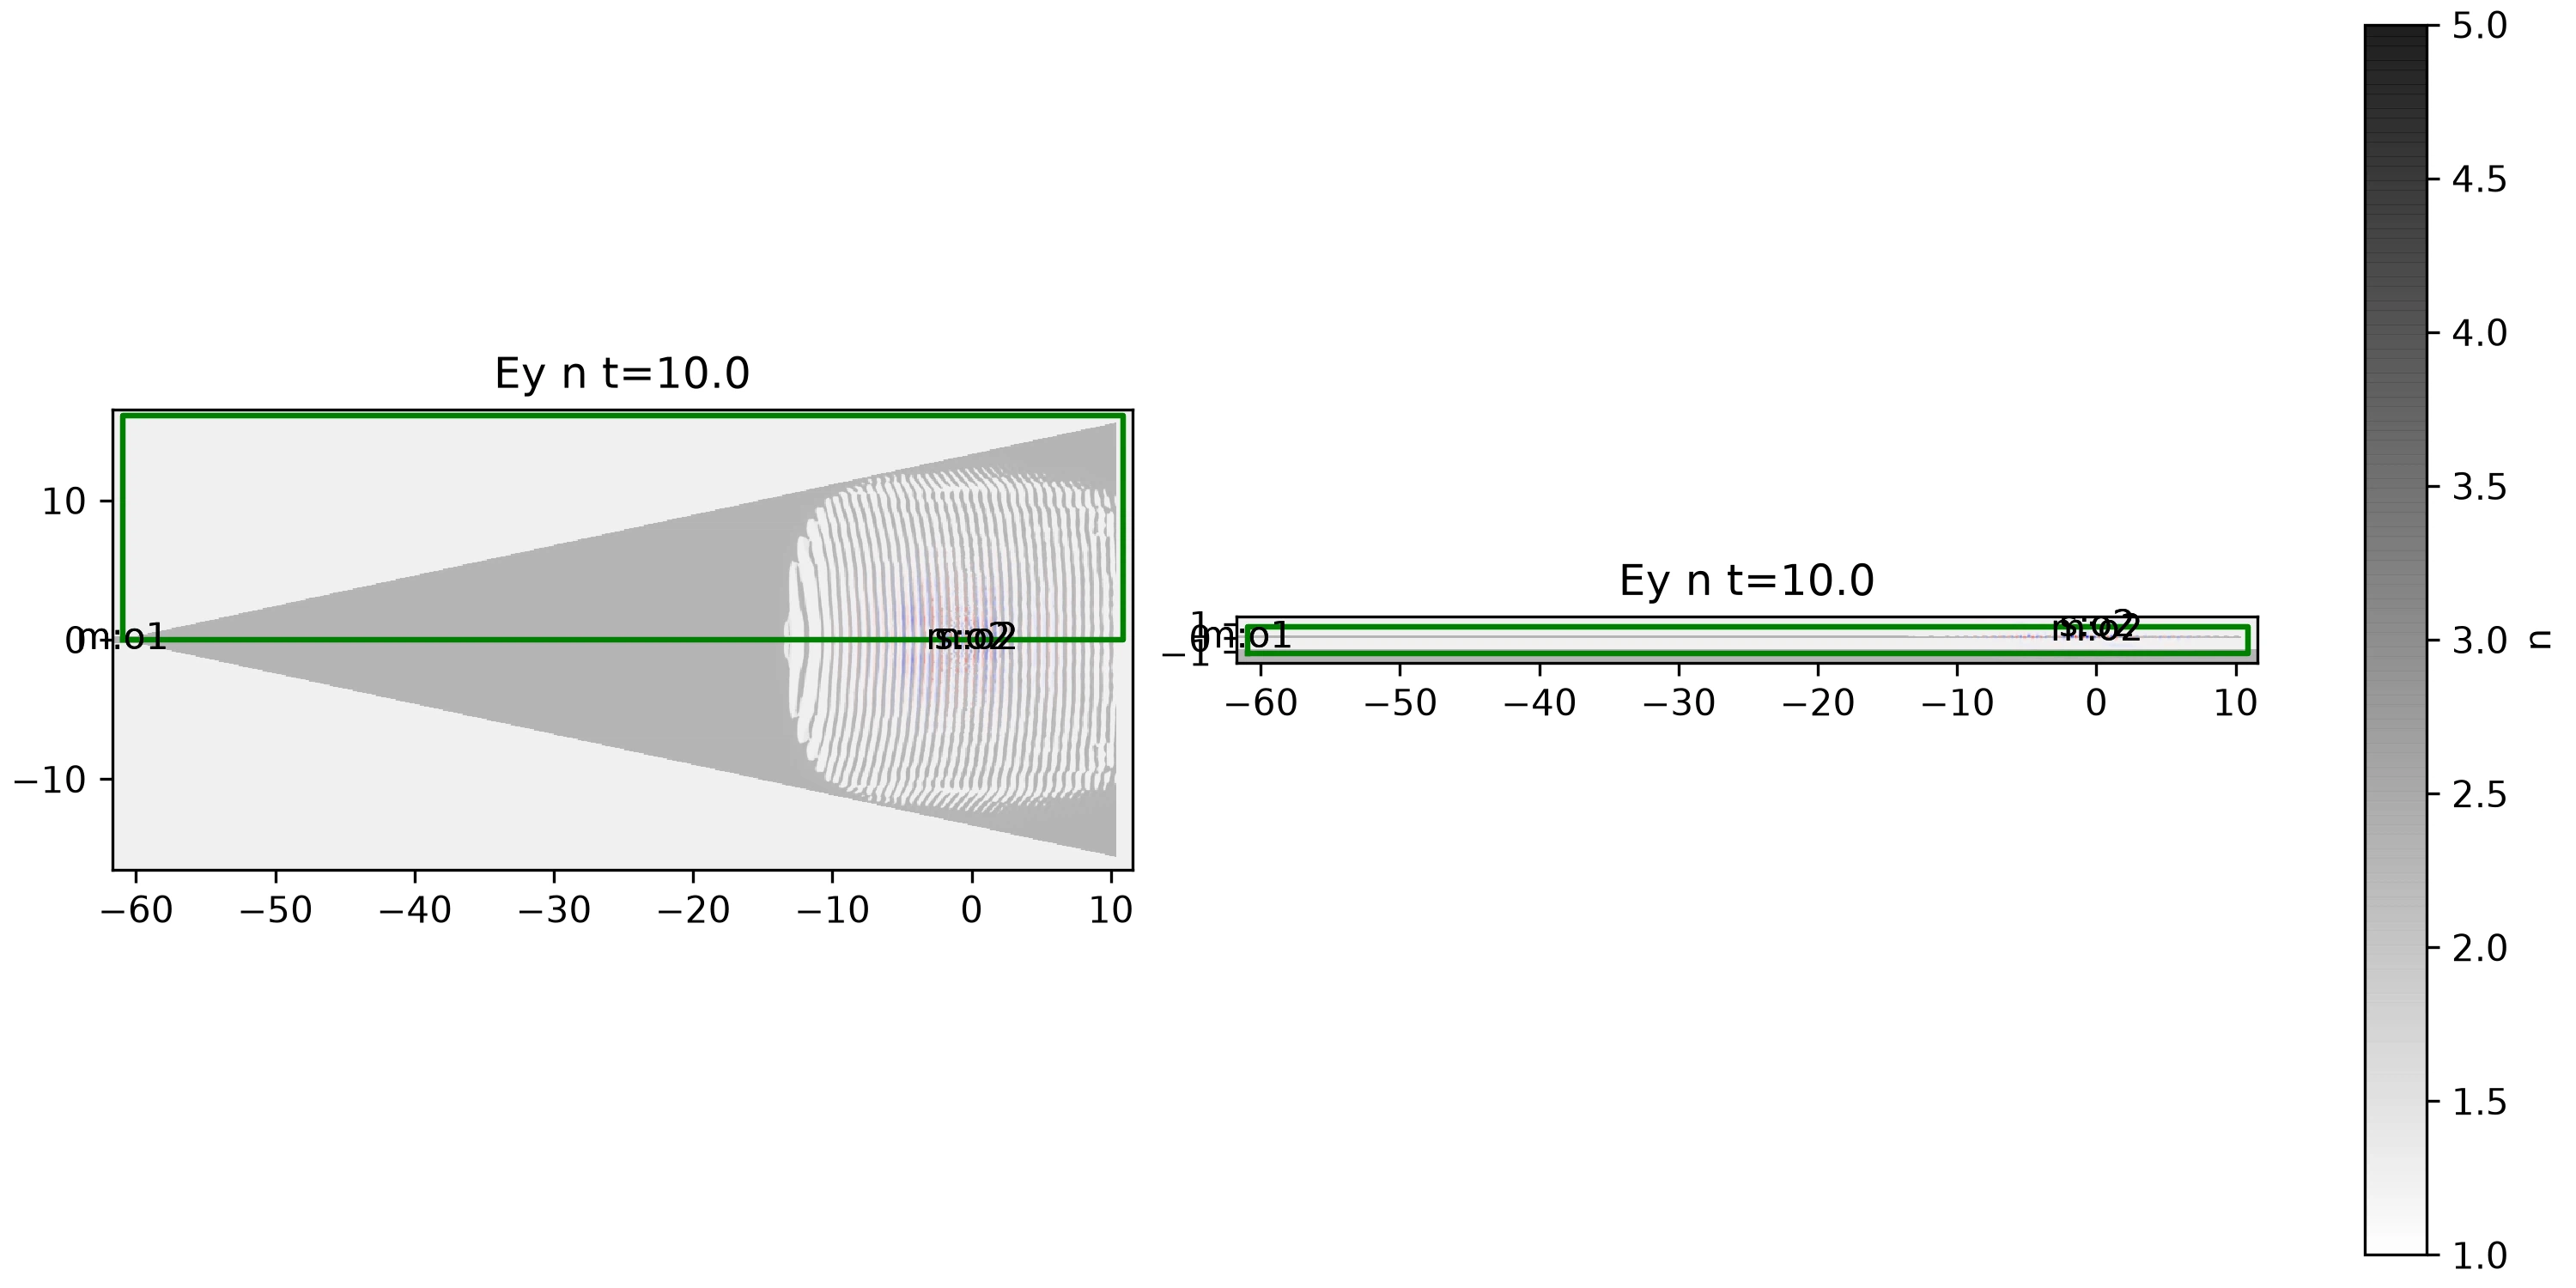

In [6]:
lumi.movie(path)